# SPM and solitons in fibres

Notebooks 117 (dispersion in fibres) and 118 (pulse broadening) treated
the fibre as a linear medium. But a single-mode fibre confines light to
an area of 80 µm² over kilometres, and even a milliwatt pulse acquires a
noticeable nonlinear phase from the Kerr effect of silica (notebook 147,
Kerr effect and self-focusing). This **self-phase modulation** (SPM)
alone broadens the spectrum; together with the anomalous dispersion of
silica above 1.3 µm it makes **solitons**, pulses that keep their shape
because the nonlinear chirp and the dispersion cancel.

The envelope obeys the nonlinear Schrödinger equation (NLSE), here in the
pyoptics convention $\exp(i(\beta z - \omega t))$ (Agrawal's form),

$$\frac{\partial A}{\partial z} = -\frac{\alpha}{2}A - \frac{i\beta_2}{2}\frac{\partial^2A}{\partial t^2}
 + \frac{\beta_3}{6}\frac{\partial^3A}{\partial t^3} + i\gamma|A|^2A,$$

with $|A|^2$ the power and the nonlinear coefficient
$\gamma = n_2\omega_0/(cA_{\rm eff})$ = 1.3 /(W km) for a standard fibre at
1550 nm. The `splitstep` module solves it: the classic split-step
Fourier method (`SS.nlse()`) and the fourth order Runge–Kutta method in
the interaction picture with Raman scattering and self-steepening
(`SS.gnlse()`). Its linear part is that of `fibrecomm.propagate()`.

1. length scales: dispersion length, nonlinear length, soliton order,
2. accuracy of the split-step methods,
3. SPM: spectral broadening and chirp, and SPM with normal dispersion,
4. the fundamental soliton,
5. higher-order solitons,
6. soliton fission and supercontinuum generation in a photonic crystal
   fibre,
7. the soliton self-frequency shift from Raman scattering,
8. SPM in a 10 Gb/s link: why launch powers stay low.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fibrecomm as FC
from pyoptics import splitstep as SS
from pyoptics.fibres import beta2_from_D
from pyoptics.ultrafast import fwhm

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

# standard single-mode fibre at 1550 nm: ps, km, W
B2 = float(beta2_from_D(17.0, 1550.0))       # ps²/km
B3 = 0.12                                    # ps³/km
GAMMA = 1.3                                  # 1/(W km)
ALPHA = 0.2/(10*np.log10(np.e))              # 0.2 dB/km as a power coefficient (1/km)
C_NM_PS = 2.99792458E5
OMEGA0 = 2*np.pi*C_NM_PS/1550.0              # rad/ps
print("SMF at 1550 nm: beta2 = {:.2f} ps²/km, gamma = {} /(W km), alpha = {:.4f} /km".format(B2, GAMMA, ALPHA))

SMF at 1550 nm: beta2 = -21.68 ps²/km, gamma = 1.3 /(W km), alpha = 0.0461 /km


## 1. Length scales

Two lengths measure the two effects for a pulse of width $T_0$ (the
$1/e$ half width of a Gaussian, the sech parameter of a soliton) and peak
power $P_0$: the **dispersion length** $L_D = T_0^2/|\beta_2|$ and the
**nonlinear length** $L_{NL} = 1/(\gamma P_0)$, over which the peak gets
one radian of nonlinear phase. Their ratio defines the **soliton order**
$N^2 = L_D/L_{NL} = \gamma P_0T_0^2/|\beta_2|$. For $N \ll 1$ dispersion
dominates (notebook 118, pulse broadening), for $N \gg 1$ SPM dominates
at first; with anomalous dispersion and $N$ near 1 or larger, solitons
form.

In [2]:
print("pulse (FWHM)   P0      L_D (km)   L_NL (km)   N")
for fw, P0 in ((100.0, 0.001), (100.0, 0.1), (10.0, 0.01), (10.0, 1.0), (1.0, 1.0), (0.1, 100.0)):
    T0 = fw/1.763
    print("{:6.1f} ps   {:7.3f} W  {:9.3g}   {:9.3g}   {:6.2f}".format(fw, P0, SS.dispersion_length(T0, B2),
                                                                     SS.nonlinear_length(P0, GAMMA),
                                                                     SS.soliton_order(T0, P0, GAMMA, B2)))

pulse (FWHM)   P0      L_D (km)   L_NL (km)   N
 100.0 ps     0.001 W        148         769     0.44
 100.0 ps     0.100 W        148        7.69     4.39
  10.0 ps     0.010 W       1.48        76.9     0.14
  10.0 ps     1.000 W       1.48       0.769     1.39
   1.0 ps     1.000 W     0.0148       0.769     0.14
   0.1 ps   100.000 W   0.000148     0.00769     0.14


A 10 Gb/s bit (100 ps) of 1 mW hardly notices either effect over 100 km
($L_D$ = 148 km, $L_{NL}$ = 770 km), but at 100 mW the nonlinearity
dominates. Picosecond pulses of a watt are solitons of order 1, and
femtosecond pulses of 100 W need only millimetres for both effects.

## 2. Accuracy of the split-step methods

The **symmetric split-step Fourier method** applies half a dispersion step
in the frequency domain, the nonlinear phase $\gamma|A|^2dz$ in the time
domain, and the other half of the dispersion step. Since the two operators
do not commute, the error per step is of third order and the global
error of second order in $dz$. **RK4IP** (Hult 2007) applies the
dispersion exactly in the interaction picture and integrates the
nonlinear term with a fourth order Runge–Kutta method: fourth order
globally, at four FFT pairs per step. The test is the second order
soliton ($N$ = 2), which compresses and splits over one soliton period
$z_0 = \pi L_D/2$ and returns to its input, against a reference with
4000 steps.

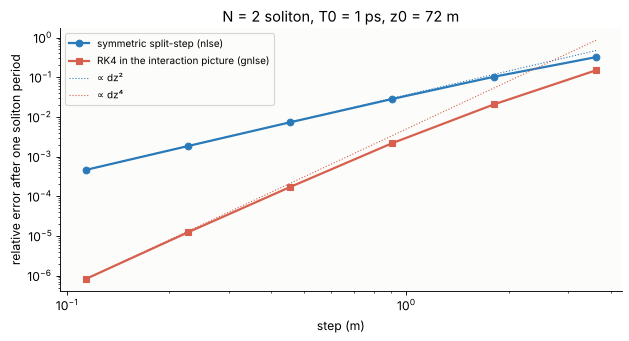

  20 steps: split-step 3.2e-01, RK4IP 1.5e-01
  40 steps: split-step 1.0e-01, RK4IP 2.1e-02
  80 steps: split-step 2.8e-02, RK4IP 2.2e-03
 160 steps: split-step 7.3e-03, RK4IP 1.7e-04
 320 steps: split-step 1.8e-03, RK4IP 1.2e-05
 640 steps: split-step 4.6e-04, RK4IP 8.2e-07


In [3]:
t = np.linspace(-40, 40, 2**11, endpoint=False)
T0 = 1.0
A2 = SS.soliton(t, T0, B2, GAMMA, N=2)
z0 = SS.soliton_period(T0, B2)
ref = SS.gnlse(t, A2, z0, [B2], GAMMA, steps=4000)
steps = np.array([20, 40, 80, 160, 320, 640])
err_ss, err_rk = [], []
for n in steps:
    err_ss.append(np.linalg.norm(SS.nlse(t, A2, z0, [B2], GAMMA, steps=n) - ref)/np.linalg.norm(ref))
    err_rk.append(np.linalg.norm(SS.gnlse(t, A2, z0, [B2], GAMMA, steps=n) - ref)/np.linalg.norm(ref))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.loglog(z0/steps*1E3, err_ss, "o-", color=BLUE, lw=2, label="symmetric split-step (nlse)")
ax.loglog(z0/steps*1E3, err_rk, "s-", color=RED, lw=2, label="RK4 in the interaction picture (gnlse)")
h = z0/steps*1E3
ax.loglog(h, err_ss[-1]*(h/h[-1])**2, color=BLUE, lw=1, ls=":", label="∝ dz²")
ax.loglog(h, err_rk[-1]*(h/h[-1])**4, color=RED, lw=1, ls=":", label="∝ dz⁴")
ax.set_xlabel("step (m)"); ax.set_ylabel("relative error after one soliton period")
ax.set_title(f"N = 2 soliton, T0 = 1 ps, z0 = {z0*1E3:.0f} m"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
for n, a, b in zip(steps, err_ss, err_rk):
    print("{:4d} steps: split-step {:.1e}, RK4IP {:.1e}".format(n, a, b))

The split-step method converges as $dz^2$ (error 5 × 10⁻⁴ with 640 steps),
RK4IP as $dz^4$ (8 × 10⁻⁷). For the same accuracy of 10⁻³ RK4IP needs
about a third of the steps, and its adaptive version (`tol=` in
`SS.gnlse()`) chooses the step from the local error, which pays when the
pulse compresses suddenly, as in section 6.

## 3. Self-phase modulation

Without dispersion the pulse keeps its shape and only acquires the phase
$\gamma|A(t)|^2L_{\rm eff}$, with the effective length
$L_{\rm eff} = (1 - e^{-\alpha L})/\alpha$ of a lossy fibre (21.7 km at most
for 0.2 dB/km). The instantaneous frequency shift $-\partial\phi/\partial t$
is negative (red) on the rising edge and positive (blue) on the falling
edge. Each frequency occurs at two times, and the two contributions
interfere: the spectrum splits into about $\phi_{\max}/\pi + 1/2$ peaks.
The rms width grows by $\sqrt{1 + 4\phi_{\max}^2/(3\sqrt{3})}$ for a
Gaussian (Agrawal, eq. 4.1.15). The left plots use a 10 ps pulse in 2 km
without dispersion.

With **normal** dispersion ($\beta_2 > 0$, a dispersion compensating
fibre, or any fibre below 1.3 µm), the red front travels faster and the
blue back slower: SPM and dispersion work together, the pulse broadens
faster than without SPM and becomes nearly rectangular with an almost
linear chirp, the basis of fibre-grating pulse compressors. The right
plot shows a 5 ps, 40 W pulse ($N$ = 5) in a fibre with
$\beta_2$ = +20 ps²/km.

0.3 W: phi_max  0.78 rad, 0.7 peaks expected, rms broadening  1.21 (formula  1.21)
1.0 W: phi_max  2.60 rad, 1.3 peaks expected, rms broadening  2.49 (formula  2.49)
3.0 W: phi_max  7.80 rad, 3.0 peaks expected, rms broadening  6.92 (formula  6.92)
6.0 W: phi_max 15.60 rad, 5.5 peaks expected, rms broadening 13.72 (formula 13.72)


normal dispersion, N = 4.8, z = 0.5 L_D: FWHM 17.36 ps with SPM,  5.59 ps without


normal dispersion, N = 4.8, z = 1.0 L_D: FWHM 31.45 ps with SPM,  7.07 ps without


normal dispersion, N = 4.8, z = 2.0 L_D: FWHM 62.15 ps with SPM, 11.18 ps without


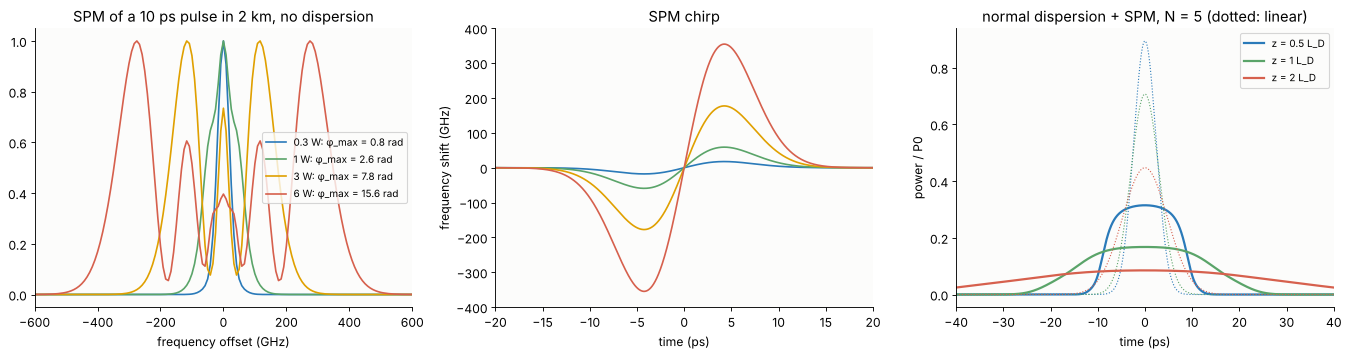

In [4]:
t = np.linspace(-60, 60, 2**12, endpoint=False)
T0 = 10/1.665                                   # 10 ps FWHM Gaussian
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for P0, c in ((0.3, BLUE), (1.0, GREEN), (3.0, ORANGE), (6.0, RED)):
    A0 = np.sqrt(P0)*np.exp(-t**2/(2*T0**2))
    L = 2.0
    A = SS.nlse(t, A0, L, gamma=GAMMA, steps=50)
    phi = SS.spm_phase(P0, GAMMA, L)
    Om, S = SS.spectrum(t, A)
    f_ghz = Om/(2*np.pi)*1E3
    axes[0].plot(f_ghz, np.abs(S)**2/np.max(np.abs(S)**2), color=c, lw=1.5, label=f"{P0:g} W: φ_max = {phi:.1f} rad")
    Om0, S0 = SS.spectrum(t, A0)
    rms = lambda w: np.sqrt(np.sum(Om**2*w)/np.sum(w))
    print("{:3.1f} W: phi_max {:5.2f} rad, {:3.1f} peaks expected, rms broadening {:5.2f} (formula {:5.2f})".format(
        P0, phi, phi/np.pi + 0.5, rms(np.abs(S)**2)/rms(np.abs(S0)**2), SS.spm_broadening(phi)))
    axes[1].plot(t, -np.gradient(np.unwrap(np.angle(A)), t)/(2*np.pi)*1E3, color=c, lw=1.5)
axes[0].set_xlim(-600, 600); axes[0].set_xlabel("frequency offset (GHz)"); axes[0].legend(fontsize=9)
axes[0].set_title("SPM of a 10 ps pulse in 2 km, no dispersion")
axes[1].set_xlim(-20, 20); axes[1].set_ylim(-400, 400); axes[1].set_xlabel("time (ps)"); axes[1].set_ylabel("frequency shift (GHz)")
axes[1].set_title("SPM chirp")
# normal dispersion: SPM + beta2 > 0 (a dispersion compensating fibre, or a fibre at 1 µm)
ax = axes[2]
T0n = 5.0/1.665
tn = np.linspace(-80, 80, 2**12, endpoint=False)
B2n = 20.0
P0n = 40.0
A0 = np.sqrt(P0n)*np.exp(-tn**2/(2*T0n**2))
L_D = SS.dispersion_length(T0n, B2n)
N_n = SS.soliton_order(T0n, P0n, GAMMA, B2n)
for L, c, ls in ((0.5*L_D, BLUE, "-"), (1*L_D, GREEN, "-"), (2*L_D, RED, "-")):
    A = SS.gnlse(tn, A0, L, [B2n], GAMMA, steps=800)
    A_lin = SS.gnlse(tn, A0, L, [B2n], 0.0, steps=10)
    ax.plot(tn, np.abs(A)**2/P0n, color=c, lw=2, label=f"z = {L/L_D:g} L_D")
    ax.plot(tn, np.abs(A_lin)**2/P0n, color=c, lw=1, ls=":")
    print("normal dispersion, N = {:.1f}, z = {:3.1f} L_D: FWHM {:5.2f} ps with SPM, {:5.2f} ps without".format(
        N_n, L/L_D, fwhm(tn, np.abs(A)**2), fwhm(tn, np.abs(A_lin)**2)))
ax.set_xlim(-40, 40); ax.set_xlabel("time (ps)"); ax.set_ylabel("power / P0")
ax.set_title(f"normal dispersion + SPM, N = {N_n:.0f} (dotted: linear)"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The rms broadening matches the formula to the last digit (1.21 to 13.7
times), and the spectra have the predicted number of peaks. With normal
dispersion the pulse is three times longer than without SPM after half a
dispersion length (17 ps against 5.6 ps) and six times after two (62 ps
against 11 ps), with the flat top and steep edges of a nearly linearly
chirped pulse.

## 4. The fundamental soliton

With **anomalous** dispersion ($\beta_2 < 0$), the red front is slowed and
the blue back is accelerated: dispersion and SPM work against each other.
For the sech pulse

$$A(t) = \sqrt{P_0}\,\mathrm{sech}(t/T_0),\qquad P_0 = \frac{|\beta_2|}{\gamma T_0^2},$$

($N$ = 1) they cancel exactly at every point, and the pulse propagates
unchanged, only acquiring the phase $\gamma P_0z/2$ (`SS.soliton()`). For a
1.76 ps pulse in a standard fibre that needs 16.7 W of peak power. An input
that is not a soliton but close to one (a Gaussian of the same energy
and width) reshapes into a soliton and sheds the rest of its energy as
dispersive waves.

fundamental soliton, T0 = 1 ps (1.76 ps FWHM): P0 = 16.7 W, z0 = 72 m


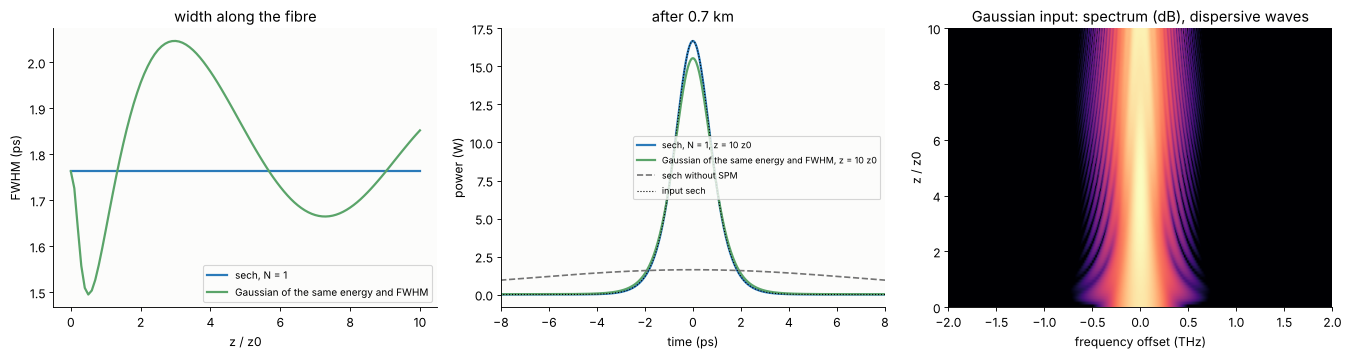

sech after 10 z0: FWHM 1.763 ps (input 1.763 ps); without SPM 18.2 ps
Gaussian after 10 z0: peak 15.54 W, FWHM 1.85 ps, 98.9 % of the energy within ±5 ps


In [5]:
t = np.linspace(-60, 60, 2**12, endpoint=False)
T0 = 1.0
P1 = abs(B2)/(GAMMA*T0**2)
z0 = SS.soliton_period(T0, B2)
L = 10*z0
print("fundamental soliton, T0 = 1 ps (1.76 ps FWHM): P0 = {:.1f} W, z0 = {:.0f} m".format(P1, z0*1E3))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
A_sech = SS.soliton(t, T0, B2, GAMMA)
E_sech = np.sum(np.abs(A_sech)**2)
Tg = 1.763*T0/1.665
A_g = np.exp(-t**2/(2*Tg**2)).astype(complex)
A_g *= np.sqrt(E_sech/np.sum(np.abs(A_g)**2))
for k, (name, A0, c) in enumerate((("sech, N = 1", A_sech, BLUE), ("Gaussian of the same energy and FWHM", A_g, GREEN))):
    A, zz, H = SS.gnlse(t, A0, L, [B2], GAMMA, steps=2000, n_save=101)
    widths = [fwhm(t, np.abs(h)**2) for h in H]
    axes[0].plot(zz/z0, widths, color=c, lw=2, label=name)
    axes[1].plot(t, np.abs(A)**2, color=c, lw=2, label=f"{name}, z = 10 z0")
A_lin = SS.gnlse(t, A_sech, L, [B2], 0.0, steps=10)
axes[1].plot(t, np.abs(A_lin)**2, color=GREY, lw=1.5, ls="--", label="sech without SPM")
axes[1].plot(t, np.abs(A_sech)**2, color="k", lw=1, ls=":", label="input sech")
axes[0].set_xlabel("z / z0"); axes[0].set_ylabel("FWHM (ps)"); axes[0].legend(fontsize=9)
axes[0].set_title("width along the fibre")
axes[1].set_xlim(-8, 8); axes[1].set_xlabel("time (ps)"); axes[1].set_ylabel("power (W)"); axes[1].legend(fontsize=8)
axes[1].set_title(f"after {L:.1f} km")
ax = axes[2]
A, zz, H = SS.gnlse(t, A_g, L, [B2], GAMMA, steps=2000, n_save=101)
Om, S = SS.spectrum(t, H, shift=True)
ax.imshow(10*np.log10(np.abs(S)**2/np.max(np.abs(S)**2) + 1E-12), aspect="auto", origin="lower", cmap="magma",
          extent=[Om[0]/(2*np.pi), Om[-1]/(2*np.pi), 0, L/z0], vmin=-50, vmax=0)
ax.set_xlim(-2, 2); ax.set_xlabel("frequency offset (THz)"); ax.set_ylabel("z / z0")
ax.set_title("Gaussian input: spectrum (dB), dispersive waves")
plt.tight_layout()
plt.show()
print("sech after 10 z0: FWHM {:.3f} ps (input {:.3f} ps); without SPM {:.1f} ps".format(
    fwhm(t, np.abs(SS.gnlse(t, A_sech, L, [B2], GAMMA, steps=2000))**2), fwhm(t, np.abs(A_sech)**2),
    fwhm(t, np.abs(A_lin)**2)))
E_out = np.sum(np.abs(A)**2)
print("Gaussian after 10 z0: peak {:.2f} W, FWHM {:.2f} ps, {:.1f} % of the energy within ±5 ps".format(
    np.max(np.abs(A)**2), fwhm(t, np.abs(A)**2), np.sum(np.abs(A[np.abs(t) < 5])**2)/E_out*100))

The sech keeps its width of 1.763 ps over 10 soliton periods (720 m),
where linear dispersion alone would have stretched it to 18 ps. The
Gaussian first compresses, then oscillates around the soliton width with
a slowly decaying breathing, keeping 99 % of its energy within ±5 ps;
the fringes on the sides of its spectrum are the dispersive waves it
sheds. Solitons were proposed for long-haul transmission (Hasegawa and
Tappert 1973) and later made the femtosecond fibre lasers of notebook 143
(Q-switching and mode-locking) possible.

## 5. Higher-order solitons

An input $N$ times the fundamental soliton (integer $N$) is a
**higher-order soliton**: a bound state of $N$ solitons that compresses,
splits and returns to its input shape after every soliton period $z_0$.
The second order soliton compresses to a narrow peak of four times the
input power at $z_0/2$; higher orders show more complex patterns. Their
spectra breathe with them.

N = 1: peak power at z0/2 =   1.0 × input peak, FWHM 1.763 ps; after z0 the shape returns to 5.5e-07


N = 2: peak power at z0/2 =   4.0 × input peak, FWHM 0.398 ps; after z0 the shape returns to 5.6e-07


N = 3: peak power at z0/2 =   2.3 × input peak, FWHM 1.478 ps; after z0 the shape returns to 1.5e-06


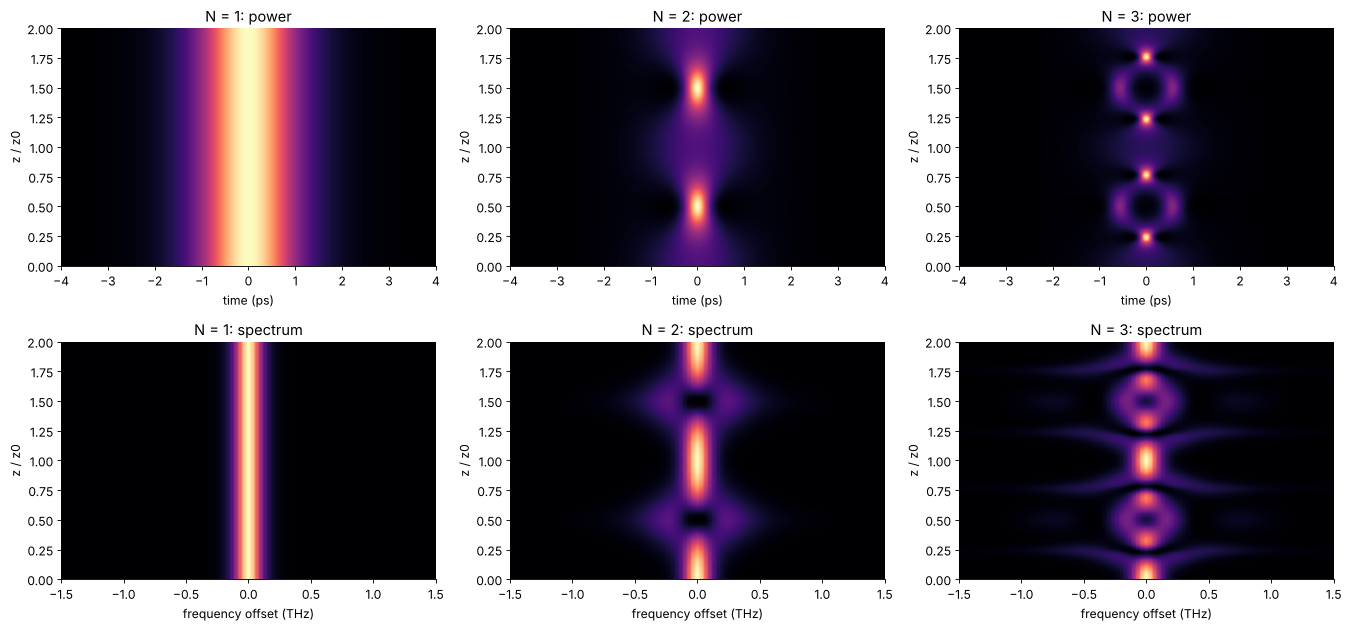

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
t = np.linspace(-15, 15, 2**11, endpoint=False)
for col, N in enumerate((1, 2, 3)):
    A0 = SS.soliton(t, T0, B2, GAMMA, N=N)
    A, zz, H = SS.gnlse(t, A0, 2*z0, [B2], GAMMA, steps=3000, n_save=201)
    P = np.abs(H)**2
    axes[0, col].imshow(P, aspect="auto", origin="lower", cmap="magma", extent=[t[0], t[-1], 0, 2])
    axes[0, col].set_xlim(-4, 4); axes[0, col].set_xlabel("time (ps)"); axes[0, col].set_ylabel("z / z0")
    axes[0, col].set_title(f"N = {N}: power")
    Om, S = SS.spectrum(t, H)
    axes[1, col].imshow(np.abs(S)**2, aspect="auto", origin="lower", cmap="magma",
                        extent=[Om[0]/(2*np.pi), Om[-1]/(2*np.pi), 0, 2])
    axes[1, col].set_xlim(-1.5, 1.5); axes[1, col].set_xlabel("frequency offset (THz)"); axes[1, col].set_ylabel("z / z0")
    axes[1, col].set_title(f"N = {N}: spectrum")
    k_half = np.argmin(np.abs(zz - z0/2))
    print("N = {}: peak power at z0/2 = {:5.1f} × input peak, FWHM {:.3f} ps; after z0 the shape returns to {:.1e}".format(
        N, P[k_half].max()/P[0].max(), fwhm(t, P[k_half]),
        np.max(np.abs(np.abs(H[100]) - np.abs(H[0])))/np.abs(H[0]).max()))
plt.tight_layout()
plt.show()

All three return to the input after $z_0$ to within 10⁻⁶, the accuracy of
the solver. The $N$ = 2 soliton reaches four times the input peak at
$z_0/2$ with a width of 0.40 ps, a fourth of the input: the compression is
used in soliton-effect pulse compressors.

## 6. Soliton fission and supercontinuum

A higher-order soliton is fragile: third-order dispersion and Raman
scattering break the bound state near the point of maximum compression,
the **fission length** $L_D/N$, into $N$ fundamental solitons of
different widths and colours, which emit dispersive waves across the zero
dispersion wavelength. This is the main mechanism of **supercontinuum
generation** in photonic crystal fibres. The example is the standard case
of Dudley, Genty and Coen (2006): 50 fs pulses of 10 kW at 835 nm, in
15 cm of a fibre with its zero dispersion wavelength at 780 nm, with the
dispersion to tenth order, $\gamma$ = 0.11 /(W m), self-steepening and
the Raman response of silica (`raman=0.18`). The solver runs adaptively
with a local error of 10⁻⁶ per step.

N = 8.7, L_D = 6.8 cm, fission length L_D/N = 7.9 mm


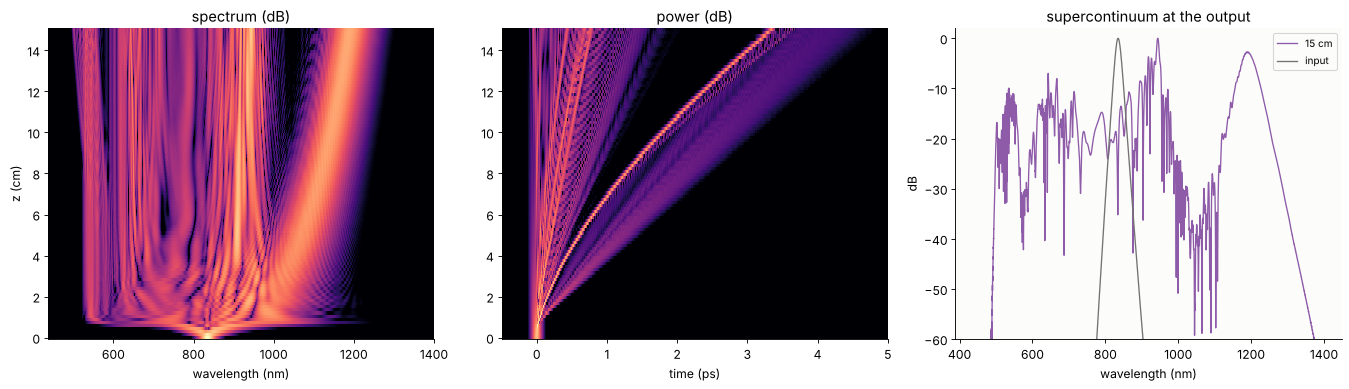

output spectrum within 30 dB of its peak: 497 to 1286 nm


In [7]:
# Dudley, Genty and Coen (2006): 835 nm, 50 fs FWHM, 10 kW in 15 cm of photonic crystal fibre; ps and m
betas_pcf = [-11.830E-3, 8.1038E-5, -9.5205E-8, 2.0737E-10, -5.3943E-13, 1.3486E-15, -2.5495E-18,
             3.0524E-21, -1.7140E-24]                     # ps^k/m
gamma_pcf, P0_pcf, T0_pcf, L_pcf = 0.11, 10E3, 0.0284, 0.15
w0_pcf = 2*np.pi*C_NM_PS/835.0
tp = np.linspace(-6.25, 6.25, 2**13, endpoint=False)
A0 = np.sqrt(P0_pcf)/np.cosh(tp/T0_pcf) + 0j
N_pcf = SS.soliton_order(T0_pcf, P0_pcf, gamma_pcf, betas_pcf[0])
print("N = {:.1f}, L_D = {:.1f} cm, fission length L_D/N = {:.1f} mm".format(
    N_pcf, SS.dispersion_length(T0_pcf, betas_pcf[0])*100, SS.fission_length(T0_pcf, betas_pcf[0], N_pcf)*1E3))
A_sc, zz_sc, H_sc = SS.gnlse(tp, A0, L_pcf, betas_pcf, gamma_pcf, omega0=w0_pcf, raman=0.18, steps=200, tol=1E-6,
                             n_save=101)
Om, S = SS.spectrum(tp, H_sc)
lam_nm = 2*np.pi*C_NM_PS/(w0_pcf + Om)
order = np.argsort(lam_nm)
lam_s = lam_nm[order]
Sdb = 10*np.log10(np.abs(S[:, order])**2/np.max(np.abs(S)**2) + 1E-30)
Pdb = 10*np.log10(np.abs(H_sc)**2/np.max(np.abs(H_sc)**2) + 1E-30)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
good = (lam_s > 400) & (lam_s < 1400)
axes[0].pcolormesh(lam_s[good], zz_sc*100, Sdb[:, good], cmap="magma", vmin=-40, vmax=0, shading="auto")
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel("z (cm)"); axes[0].set_title("spectrum (dB)")
axes[1].pcolormesh(tp, zz_sc*100, Pdb, cmap="magma", vmin=-40, vmax=0, shading="auto")
axes[1].set_xlim(-0.5, 5); axes[1].set_xlabel("time (ps)"); axes[1].set_title("power (dB)")
axes[2].plot(lam_s[good], Sdb[-1, good] - Sdb[-1, good].max(), color=PURPLE, lw=1.2, label="15 cm")
axes[2].plot(lam_s[good], Sdb[0, good] - Sdb[0, good].max(), color=GREY, lw=1.2, label="input")
axes[2].set_ylim(-60, 2); axes[2].set_xlabel("wavelength (nm)"); axes[2].set_ylabel("dB"); axes[2].legend(fontsize=9)
axes[2].set_title("supercontinuum at the output")
plt.tight_layout()
plt.show()
band = lam_s[Sdb[-1] > Sdb[-1].max() - 30]
print("output spectrum within 30 dB of its peak: {:.0f} to {:.0f} nm".format(band.min(), band.max()))

The $N$ = 8.7 soliton compresses within the first 8 mm, as predicted by the
fission length, and then breaks up. Its fragments move to longer
wavelengths (the solitons on the red side, delayed in time), while
dispersive waves appear in the normal dispersion region below 600 nm.
After 15 cm the spectrum spans 500 to 1290 nm within 30 dB: a white light
source of the brightness of a laser, used in fluorescence microscopy,
optical coherence tomography (notebook 82, OCT) and, octave spanning, to
measure the carrier envelope offset of frequency combs (notebook 143,
Q-switching and mode-locking).

## 7. Soliton self-frequency shift

The delayed Raman response of silica transfers energy from the blue to
the red side of a short soliton's spectrum: the soliton shifts
continuously to longer wavelengths, at the rate

$$\frac{d\Omega}{dz} = -\frac{8T_R|\beta_2|}{15T_0^4}$$

(Gordon 1986, `SS.ssfs_rate()`) with $T_R = f_R\int t\,h_R(t)\,dt$, 1.5 fs
for the Raman model used here. The strong $T_0^{-4}$ dependence makes it a
femtosecond effect.

  200 fs soliton: shift after 500 m  -6.31 THz (Gordon  -8.12 THz, the rate falls as T0^-4)


  300 fs soliton: shift after 500 m  -1.48 THz (Gordon  -1.60 THz, the rate falls as T0^-4)


  500 fs soliton: shift after 500 m  -0.21 THz (Gordon  -0.21 THz, the rate falls as T0^-4)


 1000 fs soliton: shift after 500 m  -0.01 THz (Gordon  -0.01 THz, the rate falls as T0^-4)


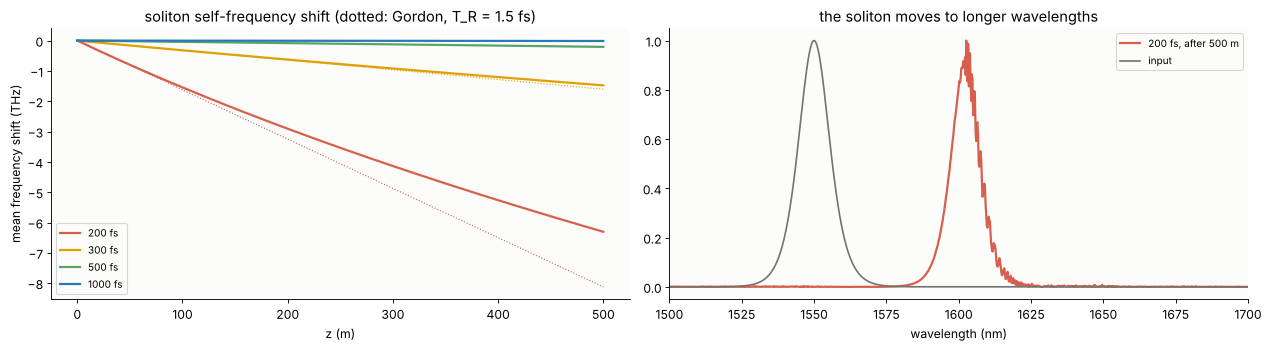

In [8]:
tr = np.linspace(-20, 20, 2**13, endpoint=False)
tt_R = np.linspace(0, 2, 400001)
T_R = 0.18*np.trapezoid(tt_R*SS.raman_response(tt_R), tt_R)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for fw, c in ((0.2, RED), (0.3, ORANGE), (0.5, GREEN), (1.0, BLUE)):
    T0r = fw/1.763
    Lr = 0.5
    A0 = SS.soliton(tr, T0r, B2, GAMMA)
    A, zz, H = SS.gnlse(tr, A0, Lr, [B2, B3], GAMMA, omega0=OMEGA0, raman=0.18, steps=1500, n_save=26)
    Om, S = SS.spectrum(tr, H)
    w = np.abs(S)**2
    shift = np.sum(Om*w, axis=1)/np.sum(w, axis=1)/(2*np.pi)       # THz
    axes[0].plot(zz*1E3, shift, color=c, lw=2, label=f"{fw*1E3:.0f} fs")
    axes[0].plot(zz*1E3, SS.ssfs_rate(T0r, B2, T_R)*zz/(2*np.pi), color=c, lw=1, ls=":")
    print("{:5.0f} fs soliton: shift after {:.0f} m {:6.2f} THz (Gordon {:6.2f} THz, the rate falls as T0^-4)".format(
        fw*1E3, Lr*1E3, shift[-1], SS.ssfs_rate(T0r, B2, T_R)*Lr/(2*np.pi)))
    if fw == 0.2:
        axes[1].plot(2*np.pi*C_NM_PS/(OMEGA0 + Om), w[-1]/w[-1].max(), color=c, lw=2, label="200 fs, after 500 m")
        axes[1].plot(2*np.pi*C_NM_PS/(OMEGA0 + Om), w[0]/w[0].max(), color=GREY, lw=1.5, label="input")
axes[0].set_xlabel("z (m)"); axes[0].set_ylabel("mean frequency shift (THz)"); axes[0].legend(fontsize=9)
axes[0].set_title(f"soliton self-frequency shift (dotted: Gordon, T_R = {T_R*1E3:.1f} fs)")
axes[1].set_xlim(1500, 1700); axes[1].set_xlabel("wavelength (nm)"); axes[1].legend(fontsize=9)
axes[1].set_title("the soliton moves to longer wavelengths")
plt.tight_layout()
plt.show()

After 500 m a 1 ps soliton has not moved, a 300 fs soliton has moved by
1.5 THz (12 nm), and a 200 fs soliton by 6.3 THz (50 nm), less than
Gordon's 8.1 THz: the formula holds for a fixed width, while the
simulated soliton also feels third-order dispersion and sheds a little
energy, which widens it and slows the shift. The
self-frequency shift is used to make widely tunable femtosecond sources
from a fixed fibre laser by changing the input power.

## 8. SPM in a fibre link

In the 10 Gb/s link of notebook 120 (fibre link) the launch power was a
few dBm. Here a PRBS7 NRZ signal is sent over 80 km of standard fibre
with mean launch powers of 0, 10 and 15 dBm, with the loss, and the linear
dispersion is then removed ideally at the receiver (a perfect dispersion
compensator), so that only the nonlinear distortion remains. The last
case reverses the sign of the dispersion.

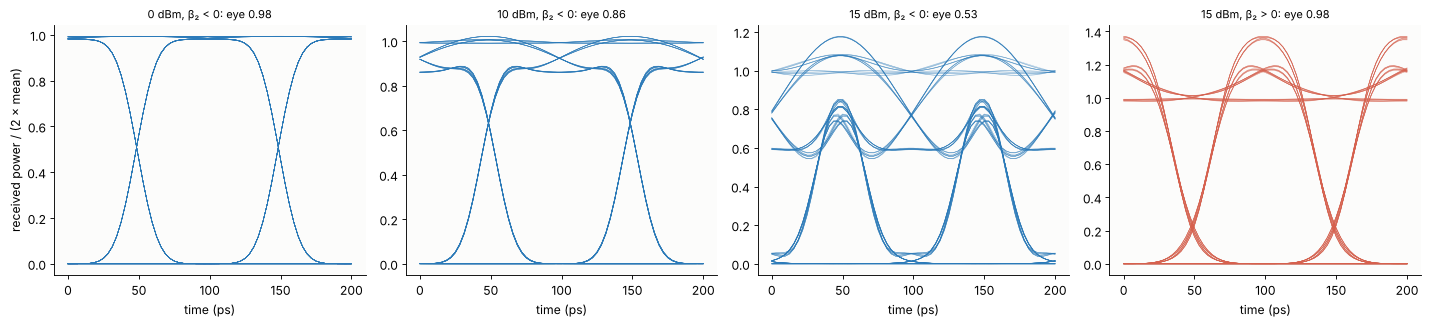

   0 dBm launched, SSMF, anomalous: eye opening 0.98 (with ideal dispersion compensation)
  10 dBm launched, SSMF, anomalous: eye opening 0.86 (with ideal dispersion compensation)
  15 dBm launched, SSMF, anomalous: eye opening 0.53 (with ideal dispersion compensation)
  15 dBm launched, normal dispersion: eye opening 0.98 (with ideal dispersion compensation)


In [9]:
bits = FC.prbs(7)
bit_rate = 10.0
L_link = 80.0
results = {}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=False)
for k, (P_dbm, D_sign) in enumerate(((0.0, 1), (10.0, 1), (15.0, 1), (15.0, -1))):
    t_b, A = FC.nrz(bits, bit_rate, samples_per_bit=32, p1=2*FC.mw(P_dbm))        # mean power P_dbm
    # SSMF (anomalous) or, for comparison, a fibre with the opposite sign of dispersion
    out = SS.gnlse(t_b, A, L_link, [D_sign*B2], GAMMA*1E-3, alpha=ALPHA, steps=800)  # gamma per mW
    # ideal dispersion compensation at the receiver: undo the linear dispersion of the whole link
    out = FC.propagate(t_b, out, L_link, beta2=-D_sign*B2)
    P_rx = np.abs(out)**2
    tau, traces = FC.eye_diagram(t_b, P_rx, bit_rate, offset=50.0)       # bit centred in the eye
    eye = FC.eye_opening(traces, bits=np.roll(bits, -1))
    norm = np.mean(P_rx)*2
    results[(P_dbm, D_sign)] = eye/norm
    ax = axes[k]
    ax.plot(tau, (traces/norm).T, color=BLUE if D_sign > 0 else RED, lw=0.4, alpha=0.5)
    ax.set_title("{:.0f} dBm, β₂ {} 0: eye {:.2f}".format(P_dbm, "<" if D_sign > 0 else ">", eye/norm), fontsize=10)
    ax.set_xlabel("time (ps)")
axes[0].set_ylabel("received power / (2 × mean)")
plt.tight_layout()
plt.show()
for (P_dbm, s), e in results.items():
    print("{:4.0f} dBm launched, {}: eye opening {:.2f} (with ideal dispersion compensation)".format(
        P_dbm, "SSMF, anomalous" if s > 0 else "normal dispersion", e))

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 128 s


At 0 dBm the eye is unchanged (0.98 of its full opening). At 10 dBm
(nonlinear phase about 0.6 rad on the ones) the ones show a ripple and
the eye closes to 0.86, at 15 dBm to 0.53: the nonlinear phase changes
the spectrum of the signal, and the dispersion of the fibre turns it into
intensity distortion that no linear compensator can remove. With the
opposite sign of dispersion the same power leaves the eye open (with
overshoots on the ones): the penalty is not SPM alone but its interplay
with dispersion, and it depends on the sign and the distribution of the
dispersion along the link. This is why links keep their launch power at a
few mW per channel, why amplifier spacing and dispersion maps are
designed together, and why wavelength division multiplexed systems add
cross-phase modulation and four-wave mixing between channels to the
budget.

## Summary

- **Length scales:** $L_D = T_0^2/|\beta_2|$, $L_{NL} = 1/(\gamma P_0)$,
  soliton order $N^2 = L_D/L_{NL}$.
- **Split-step methods:** symmetric split-step converges as $dz^2$,
  RK4IP as $dz^4$.
- **SPM:** the spectrum broadens by $\sqrt{1 + 4\phi_{\max}^2/(3\sqrt3)}$
  into $\phi_{\max}/\pi + 1/2$ peaks; with normal dispersion the pulse
  becomes rectangular and linearly chirped.
- **Solitons:** $P_0 = |\beta_2|/(\gamma T_0^2)$ (16.7 W for 1.76 ps in
  standard fibre) propagate unchanged; higher orders return every
  $z_0 = \pi L_D/2$.
- **Supercontinuum:** soliton fission at $L_D/N$, 500 to 1290 nm from
  50 fs pulses at 835 nm in 15 cm of photonic crystal fibre.
- **Raman:** femtosecond solitons shift to the red as $T_0^{-4}$.
- **Links:** SPM with dispersion closes the eye of a 10 Gb/s link above
  about 10 dBm launch power, even with ideal dispersion compensation.

## References

- G. P. Agrawal, *Nonlinear Fiber Optics*, 6th ed., Academic Press
  (2019), chapters 2 to 5 and 12.
- G. P. Agrawal, *Fiber-Optic Communication Systems*, 4th ed., Wiley
  (2010), chapter 9.
- A. Hasegawa and F. Tappert, "Transmission of stationary nonlinear
  optical pulses in dispersive dielectric fibers. I. Anomalous
  dispersion", Appl. Phys. Lett. 23, 142–144 (1973).
- L. F. Mollenauer, R. H. Stolen and J. P. Gordon, "Experimental
  observation of picosecond pulse narrowing and solitons in optical
  fibers", Phys. Rev. Lett. 45, 1095–1098 (1980).
- J. Hult, "A fourth-order Runge–Kutta in the interaction picture method
  for simulating supercontinuum generation in optical fibers", J.
  Lightwave Technol. 25, 3770–3775 (2007).
- J. M. Dudley, G. Genty and S. Coen, "Supercontinuum generation in
  photonic crystal fiber", Rev. Mod. Phys. 78, 1135–1184 (2006).
- J. P. Gordon, "Theory of the soliton self-frequency shift", Opt. Lett.
  11, 662–664 (1986).
- K. J. Blow and D. Wood, "Theoretical description of transient
  stimulated Raman scattering in optical fibers", IEEE J. Quantum
  Electron. 25, 2665–2673 (1989).